# Lab 3 - Millions of TVs, Who Is Watching?
Name: Полєжаєв Єгор Олексійович | Polezhayev Yehor Oleksiyovych | Group: КМ-41


## Setup


In [8]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

# times to Eastern
acr_sessions["start_et"] = acr_sessions.start_utc.dt.tz_convert("US/Eastern").dt.tz_localize(None)
acr_sessions["end_et"] = acr_sessions.end_utc.dt.tz_convert("US/Eastern").dt.tz_localize(None)
acr_sessions["dur_min"] = (acr_sessions.end_et - acr_sessions.start_et).dt.total_seconds() / 60

def bdate(ts):
    if ts.hour < 6:
        return (ts - pd.Timedelta(days=1)).date()
    return ts.date()

acr_sessions["bdate"] = acr_sessions.start_et.apply(bdate)

# edit rule
acr = acr_sessions[acr_sessions.dur_min >= 1].copy()

# panel households for the two weeks
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights.broadcast_date).dt.date
H = daily_weights[(daily_weights.resp_type == "H") &
                  (daily_weights.broadcast_date >= pd.to_datetime("2024-10-14").date()) &
                  (daily_weights.broadcast_date <= pd.to_datetime("2024-10-27").date())]


## Task 1.1 - Five questions


**Answer:** 

| | acr_sessions | Lab 1 viewings |
|---|---|---|
| grain | one session on one TV | one session on one respondent |
| key | session_id | respondent_id + start |
| coverage | opted-in smart TVs, any network, 2 weeks | panel homes/persons, 10 networks |
| weight | none | daily weight |
| provenance | ACR fingerprint of the screen | people-meter panel |

Biggest difference is weight (and that the TVs are a convenience sample, not a probability sample).


## Task 1.2 - Size and shape


In [9]:
print("TVs:", acr_sessions.tv_id.nunique())
print("Sessions:", len(acr_sessions))
print("Broadcast days:", acr_sessions.bdate.nunique())
print("Average TVs in-tab per day:", round(acr.groupby("bdate").tv_id.nunique().mean(), 1))
print("Hours per TV per day, raw:", round(acr_sessions.dur_min.sum() / 60 / acr.groupby("bdate").tv_id.nunique().sum(), 2))
print("Hours per TV per day, after edit rule:", round(acr.dur_min.sum() / 60 / acr.groupby("bdate").tv_id.nunique().sum(), 2))
print("Share of sessions dropped:", round((acr_sessions.dur_min < 1).mean(), 3))


TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.7
Share of sessions dropped: 0.299


## Task 1.3 - What the TV could not see


In [10]:
print(acr.groupby("session_type").dur_min.sum() / acr.dur_min.sum())
print(acr.groupby("input_source").dur_min.sum() / acr.dur_min.sum())
print("Share of TV-on hours unknown (%):", round(100 * acr[acr.session_type == "unknown"].dur_min.sum() / acr.dur_min.sum(), 1))


session_type
app        0.257003
dvr        0.025042
live       0.321542
unknown    0.396413
Name: dur_min, dtype: float64
input_source
antenna             0.086237
built_in_app        0.307434
cable_box           0.275517
game_or_disc        0.024107
satellite_box       0.075956
streaming_device    0.230749
Name: dur_min, dtype: float64
Share of TV-on hours unknown (%): 39.6


**Answer:** A real feed has more unknown because the fingerprint library only covers the big live networks. Streaming apps and anything played from a game console or disc usually end up as unknown.


## Task 2.1 - Match


In [11]:
ip_n = hh_attributes.groupby("hashed_ip").size()
tvs = acr_sessions.drop_duplicates("tv_id")[["tv_id", "hashed_ip"]]
m = tvs.merge(ip_n.rename("n_hh"), on="hashed_ip", how="left")
m["n_hh"] = m.n_hh.fillna(0)
print("Matched to one household (%):", round(100 * (m.n_hh == 1).mean(), 1))
print("Shared IP, unresolved (%):", round(100 * (m.n_hh > 1).mean(), 1))
print("Not matched (%):", round(100 * (m.n_hh == 0).mean(), 1))


Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** An IP is a weak key because one address is often shared by several households (apartments, offices) and because IPs change. When several homes share the same hashed IP the TV cannot be linked to one household.


## Task 2.2 - Profile


In [12]:
matched_ips = ip_n[ip_n == 1].index
matched = tvs[tvs.hashed_ip.isin(matched_ips)].merge(hh_attributes, on="hashed_ip")

hh_w = H.groupby("respondent_id").weight.mean().reset_index()
reg_map = {841: "Northeast", 842: "Midwest", 843: "South", 844: "West"}
inc_map = {811: "Under $25k", 812: "$25k-$50k", 813: "$50k-$75k", 814: "$75k-$100k", 815: "$100k-$150k", 816: "$150k+"}
reg = viewer_attributes[viewer_attributes.attr_id.isin(reg_map)].copy()
reg["region"] = reg.attr_id.map(reg_map)
inc = viewer_attributes[viewer_attributes.attr_id.isin(inc_map)].copy()
inc["income"] = inc.attr_id.map(inc_map)
panel = hh_w.merge(reg[["respondent_id", "region"]], on="respondent_id").merge(inc[["respondent_id", "income"]], on="respondent_id")
tot_w = panel.weight.sum()

def inc3(s):
    if s in ["Under $25k", "$25k-$50k"]: return "Under $50k"
    if s in ["$50k-$75k", "$75k-$100k"]: return "$50-100k"
    return "$100k+"

matched["inc3"] = matched.income_band.map(inc3)
panel["inc3"] = panel.income.map(inc3)

fp_reg = matched.region.value_counts(normalize=True)
pan_reg = panel.groupby("region").weight.sum() / tot_w
print(pd.DataFrame({"footprint": fp_reg, "panel": pan_reg, "index": (fp_reg / pan_reg * 100).round(0)}).round(3))

fp_inc = matched.inc3.value_counts(normalize=True)
pan_inc = panel.groupby("inc3").weight.sum() / tot_w
print(pd.DataFrame({"footprint": fp_inc, "panel": pan_inc, "index": (fp_inc / pan_inc * 100).round(0)}).round(3))


           footprint  panel  index
region                            
Midwest        0.201  0.210   96.0
Northeast      0.150  0.170   88.0
South          0.383  0.379  101.0
West           0.266  0.241  110.0
            footprint  panel  index
inc3                               
$100k+          0.421  0.350  120.0
$50-100k        0.320  0.289  111.0
Under $50k      0.259  0.361   72.0


**Answer:** Higher income and the West are over-represented; lower income and the Northeast are under-represented. Opted-in smart-TV owners tend to be more affluent.


## Task 2.3 - Ratings


In [13]:
intab = acr.groupby("bdate").tv_id.nunique()
live = acr[acr.session_type == "live"]

rows = []
for _, t in reference_ratings.merge(programs[["telecast_id", "network_code", "program_name", "broadcast_date", "start_ts", "end_ts"]], on="telecast_id").iterrows():
    day = pd.to_datetime(t.broadcast_date).date()
    day_live = live[(live.bdate == day) & (live.network_code == t.network_code)]
    ov = day_live[(day_live.start_et < t.end_ts) & (day_live.end_et > t.start_ts)].copy()
    ov["ov_min"] = ((ov.end_et.clip(upper=t.end_ts) - ov.start_et.clip(lower=t.start_ts)).dt.total_seconds() / 60).clip(0)
    watched = ov[ov.ov_min >= 1].tv_id.nunique()
    rating = watched / intab.loc[day] * 100
    rows.append([t.program_name, t.network_code, round(rating, 1), t.hh_rating, round(rating / t.hh_rating, 2)])
print(pd.DataFrame(rows, columns=["telecast", "network", "TVs HH rating", "reference", "ratio"]))


                               telecast network  TVs HH rating  reference  \
0                        MLB Postseason     FOX           16.5      25.86   
1                          NFL Football     NBC           21.2      33.14   
2                                  NCIS     CBS            5.4      10.56   
3                               Hannity     FNC            0.8       2.30   
4                     Unsellable Houses    HGTV            2.1       3.69   
5         Halloween Baking Championship    FOOD            1.0       1.63   
6                          Grotesquerie      FX            2.3       3.53   
7  The Real Housewives of New York City   BRAVO            0.7       1.23   

   ratio  
0   0.64  
1   0.64  
2   0.51  
3   0.36  
4   0.57  
5   0.60  
6   0.64  
7   0.60  


**Answer:** All ratings are too low. Hannity is the furthest off (ratio 0.36); the sports games and Grotesquerie are closest (about 0.64). This matches the profile: the footprint has too few older homes, so older-skewing programs come out lowest.


## Task 3.1 - Hours per home


In [14]:
TEN = ["ABC", "CBS", "NBC", "FOX", "FNC", "FX", "BRAVO", "HGTV", "FOOD", "HIST"]
live_ten = acr[(acr.session_type == "live") & (acr.network_code.isin(TEN))]
tv_days = acr.groupby("bdate").tv_id.nunique().sum()
print("Live hours per TV per day (ten networks):", round(live_ten.dur_min.sum() / 60 / tv_days, 2))

view_h = viewings[viewings.resp_type == "H"].copy()
view_h["start_ts"] = pd.to_datetime(view_h.start_ts)
view_h["end_ts"] = pd.to_datetime(view_h.end_ts)
view_h["dur_min"] = (view_h.end_ts - view_h.start_ts).dt.total_seconds() / 60
view_h["bdate"] = view_h.start_ts.apply(bdate)
view_h = view_h[(view_h.bdate >= pd.to_datetime("2024-10-14").date()) &
                (view_h.bdate <= pd.to_datetime("2024-10-27").date()) &
                (view_h.network_code.isin(TEN))]
view_h = view_h.drop(columns=["weight"], errors="ignore")
v = view_h.merge(H[["respondent_id", "broadcast_date", "weight"]],
                 left_on=["respondent_id", "bdate"], right_on=["respondent_id", "broadcast_date"])
w_hours = (v.dur_min / 60 * v.weight).sum()
hh_days_w = H.groupby("broadcast_date").weight.sum().sum()
print("Live hours per panel household per day (ten networks):", round(w_hours / hh_days_w, 2))


Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92


**Answer:** Hours per TV are lower. A home has about 2.6 sets and only about 1.1 of the same brand, so the footprint only sees one set.


## Task 3.2 - Network shares


In [15]:
tv_share = live_ten.groupby("network_code").dur_min.sum() / live_ten.dur_min.sum()
pan_share = v.groupby("network_code").apply(lambda g: (g.dur_min / 60 * g.weight).sum()) / w_hours
print(pd.DataFrame({"share in TVs": tv_share, "share in panel": pan_share}).round(3).sort_values("share in TVs", ascending=False))


              share in TVs  share in panel
network_code                              
NBC                  0.214           0.206
FOX                  0.201           0.194
ABC                  0.196           0.187
CBS                  0.182           0.196
FNC                  0.085           0.110
HGTV                 0.034           0.031
FX                   0.028           0.022
FOOD                 0.024           0.022
HIST                 0.019           0.019
BRAVO                0.016           0.013


## Task 3.3 - What each can see


**Answer:** The panel sees people, other sets in the home, and co-viewing. The smart-TV data sees any US network (not only the ten), apps, and second-by-second activity on the measured set.


## Task 4.1 - Daily plots


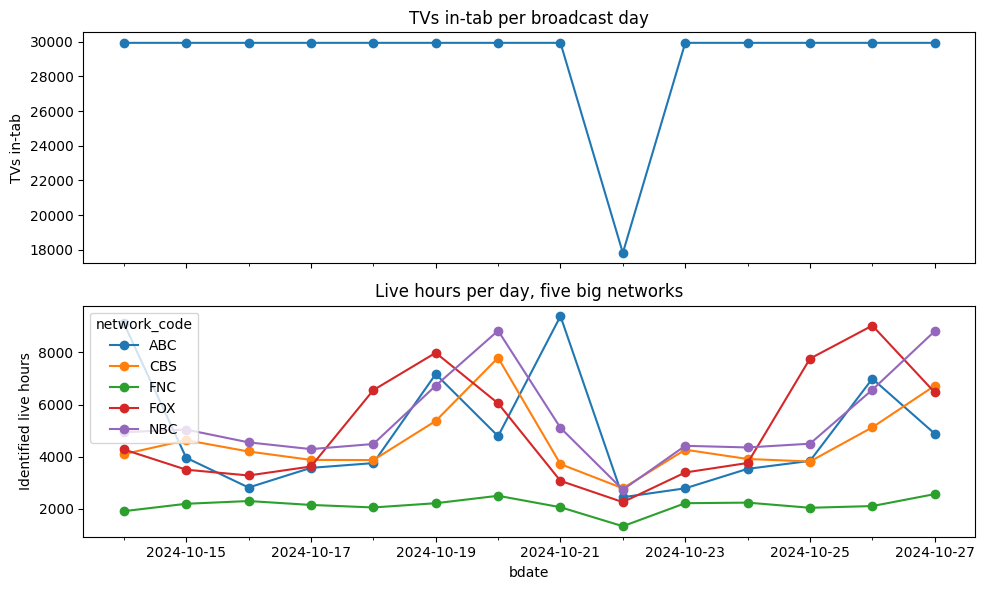

In [16]:
BIG = ["ABC", "CBS", "NBC", "FOX", "FNC"]
intab_day = acr.groupby("bdate").tv_id.nunique()
live_big = acr[(acr.session_type == "live") & (acr.network_code.isin(BIG))]
hours_day = (live_big.groupby(["bdate", "network_code"]).dur_min.sum() / 60).unstack().fillna(0)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
intab_day.plot(ax=axes[0], marker="o")
axes[0].set_ylabel("TVs in-tab")
axes[0].set_title("TVs in-tab per broadcast day")
hours_day.plot(ax=axes[1], marker="o")
axes[1].set_ylabel("Identified live hours")
axes[1].set_title("Live hours per day, five big networks")
plt.tight_layout()
plt.show()


## Task 4.2 - Spike and broken day


In [17]:
print("Biggest spike (date, network): 2024-10-21, ABC")
print("Broken day (date):", intab_day.idxmin())


Biggest spike (date, network): 2024-10-21, ABC
Broken day (date): 2024-10-22


**Answer:** Biggest spike is ABC on 2024-10-21 (Monday Night Football). On 2024-10-22 the number of in-tab TVs drops by about half; that is a data problem, not an audience change. Flag or drop the day so ratings are not distorted.


## Task 5.1 - Sampling error vs bias


In [18]:
def se(p, n):
    return np.sqrt(p * (1 - p) / n) * 100

panel_intab = H.groupby("broadcast_date").respondent_id.nunique()
gaps = {"Sunday Night Football": -11.9, "Hannity": -1.5, "Unsellable Houses": -1.6}
rows = []
for name, p, day in [("Sunday Night Football", 0.3314, "2024-10-27"),
                     ("Hannity", 0.0230, "2024-10-16"),
                     ("Unsellable Houses", 0.0369, "2024-10-16")]:
    d = pd.to_datetime(day).date()
    rows.append([name, round(se(p, intab.loc[d]), 2), round(se(p, panel_intab.loc[d]), 2), gaps[name]])
print(pd.DataFrame(rows, columns=["telecast", "SE footprint", "SE panel", "TVs rating - reference"]))


                telecast  SE footprint  SE panel  TVs rating - reference
0  Sunday Night Football          0.27      0.75                   -11.9
1                Hannity          0.09      0.24                    -1.5
2      Unsellable Houses          0.11      0.30                    -1.6


**Answer:** The bias is much bigger than the sampling error in every case. More data shrinks the SE but does not shrink the bias.


## Task 5.2 - Answer to the planner


**Answer:** For Sunday Night Football the feed gives a household rating of about 21, roughly 12 points below the currency. It cannot see people, other sets, most apps, or homes that opted out or did not match on IP. The sample is skewed toward higher-income homes, so older-skewing programs come out too low. Sampling error is small, but the bias is large and will not disappear with more of the same data. Before using it for planning I would need weights that correct the skew.


## Bonus


In [19]:
t = programs[programs.telecast_id == 1021823].iloc[0]
start, end = pd.to_datetime(t.start_ts), pd.to_datetime(t.end_ts)
bdate = pd.to_datetime(t.broadcast_date).date()

view = viewings.copy()
view["start_ts"] = pd.to_datetime(view.start_ts)
view["end_ts"] = pd.to_datetime(view.end_ts)

def overlap(df):
    return ((df.end_ts.clip(upper=end) - df.start_ts.clip(lower=start)).dt.total_seconds() / 60).clip(0)

h = view[(view.resp_type == "H") & (view.network_code == "NBC")]
h_watched = h[overlap(h) >= 1].respondent_id.unique()
p = view[view.resp_type.isin(["R", "L"]) & (view.network_code == "NBC")]
p_watched = p[overlap(p) >= 1].respondent_id.unique()

age = viewer_attributes[viewer_attributes.attr_id == 300][["respondent_id", "value"]].rename(columns={"value": "age"})
age["age"] = pd.to_numeric(age.age, errors="coerce")
a2554 = set(age[(age.age >= 25) & (age.age <= 54)].respondent_id)
p_a = [x for x in p_watched if x in a2554]

day_w = daily_weights[daily_weights.broadcast_date == bdate]
h_w = day_w[(day_w.respondent_id.isin(h_watched)) & (day_w.resp_type == "H")].weight.sum()
p_w = day_w[(day_w.respondent_id.isin(p_a)) & (day_w.resp_type.isin(["R", "L"]))].weight.sum()
vpvh = p_w / h_w
print("VPVH A25-54:", round(vpvh, 2))

hh_univ = day_w[day_w.resp_type == "H"].weight.sum()
all_p = day_w[day_w.resp_type.isin(["R", "L"])].merge(age, on="respondent_id")
a_univ = all_p[(all_p.age >= 25) & (all_p.age <= 54)].weight.sum()
print("A25-54 rating (persons):", round(21.2 * vpvh * (hh_univ / a_univ), 1))


VPVH A25-54: 0.51
A25-54 rating (persons): 11.1


**Answer:** This assumes the smart-TV homes have the same VPVH as the panel homes. If the footprint homes are demographically different the number will not transfer.
